In [37]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#loading the data set & inspecting the data set structure

df = pd.read_csv('/content/drive/MyDrive/EXIT TEST/G3.csv')
df.shape

(1755, 28)

In [12]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1755 entries, 0 to 1754
Data columns (total 28 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   enterprise_group_id             1755 non-null   object 
 1   display_name                    1755 non-null   object 
 2   enterprise_group_name           1755 non-null   object 
 3   group_root_lei                  1755 non-null   object 
 4   enterprise_group_jurisdiction   1755 non-null   object 
 5   enterprise_group_entity_status  1755 non-null   object 
 6   website                         1716 non-null   object 
 7   company_type                    1753 non-null   object 
 8   employees                       1656 non-null   float64
 9   employees_year                  1655 non-null   float64
 10  revenue                         1654 non-null   float64
 11  revenue_currency                1654 non-null   object 
 12  revenue_year                    16

In [25]:
df.head()

,enterprise_group_id,display_name,enterprise_group_name,group_root_lei,enterprise_group_jurisdiction,enterprise_group_entity_status,website,company_type,employees,employees_year,...,market_cap_date,legal_units_count,direct_subsidiaries_count,max_hierarchy_depth,is_standalone_entity,website_source,employees_source,revenue_source,net_income_source,market_cap_source
0,EG_03260722,Morgan Stanley,MORGAN STANLEY,IGJSJL3JD5P30I6NJZ34,US-DE,ACTIVE,morganstanley.com,PUBLIC,83000.0,2025.0,...,2025-12-31,1013,173.0,8.0,False,morganstanley.com,sec.gov,sec.gov,sec.gov,finance.yahoo.com
1,EG_03256960,Bank of America,BANK OF AMERICA CORPORATION,9DJT3UXIJIZJI4WXO774,US-DE,ACTIVE,bankofamerica.com,PUBLIC,213000.0,2025.0,...,2025-12-31,761,155.0,5.0,False,bankofamerica.com,sec.gov,sec.gov,https://investor.bankofamerica.com/regulatory-...,macrotrends.net
2,EG_01804232,Citigroup,CITIGROUP INC.,6SHGI4ZSSLCXXQSBB395,US-DE,ACTIVE,citigroup.com,PUBLIC,226000.0,2025.0,...,2025-12-31,742,22.0,9.0,False,citigroup.com,sec.gov,tradingview.com,tradingview.com,uk.finance.yahoo.com
3,EG_02027196,Goldman Sachs,"THE GOLDMAN SACHS GROUP, INC.",784F5XWPLTWKTBV3E584,US-DE,ACTIVE,https://www.goldmansachs.com,PUBLIC,47400.0,2025.0,...,2025-12-31,568,190.0,7.0,False,goldmansachs.com,sec.gov,goldmansachs.com,goldmansachs.com,finance.yahoo.com
4,EG_03266820,Siemens,Siemens Aktiengesellschaft,W38RGI023J3WT1HWRP32,DE,ACTIVE,siemens.com,PUBLIC,318000.0,2025.0,...,2025-09-30,568,454.0,3.0,False,siemens.com,siemens.com,siemens.com,siemens.com,siemens.com


In [8]:
df.columns

Index(['enterprise_group_id', 'display_name', 'enterprise_group_name',
       'group_root_lei', 'enterprise_group_jurisdiction',
       'enterprise_group_entity_status', 'website', 'company_type',
       'employees', 'employees_year', 'revenue', 'revenue_currency',
       'revenue_year', 'net_income', 'net_income_currency', 'net_income_year',
       'market_cap', 'market_cap_currency', 'market_cap_date',
       'legal_units_count', 'direct_subsidiaries_count', 'max_hierarchy_depth',
       'is_standalone_entity', 'website_source', 'employees_source',
       'revenue_source', 'net_income_source', 'market_cap_source'],
      dtype='object')

In [11]:
# Identify numerical and categorical columns
numerical_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(exclude=['number']).columns.tolist()

print(f"Numerical features ({len(numerical_cols)}):\n{numerical_cols}\n")
print(f"Categorical/Other features ({len(categorical_cols)}):\n{categorical_cols}")

Numerical features (10):
['employees', 'employees_year', 'revenue', 'revenue_year', 'net_income', 'net_income_year', 'market_cap', 'legal_units_count', 'direct_subsidiaries_count', 'max_hierarchy_depth']

Categorical/Other features (18):
['enterprise_group_id', 'display_name', 'enterprise_group_name', 'group_root_lei', 'enterprise_group_jurisdiction', 'enterprise_group_entity_status', 'website', 'company_type', 'revenue_currency', 'net_income_currency', 'market_cap_currency', 'market_cap_date', 'is_standalone_entity', 'website_source', 'employees_source', 'revenue_source', 'net_income_source', 'market_cap_source']


In [15]:
#checking for duplicate values and missing values

print("Missing values per column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values per column:
enterprise_group_id                 0
display_name                        0
enterprise_group_name               0
group_root_lei                      0
enterprise_group_jurisdiction       0
enterprise_group_entity_status      0
website                            39
company_type                        2
employees                          99
employees_year                    100
revenue                           101
revenue_currency                  101
revenue_year                      102
net_income                        156
net_income_currency               156
net_income_year                   156
market_cap                        531
market_cap_currency               528
market_cap_date                   531
legal_units_count                   0
direct_subsidiaries_count           8
max_hierarchy_depth                 8
is_standalone_entity                0
website_source                     35
employees_source                   91
revenue_source         

In [16]:
#summary statics
df.describe()


,employees,employees_year,revenue,revenue_year,net_income,net_income_year,market_cap,legal_units_count,direct_subsidiaries_count,max_hierarchy_depth
count,1.656000e+03,1655.000000,1.654000e+03,1653.000000,1.599000e+03,1599.000000,1.224000e+03,1755.000000,1747.000000,1747.000000
mean,3.989013e+04,2024.951057,9.050901e+11,2024.923775,7.895350e+10,2024.914321,2.057347e+12,34.330484,17.531196,2.038351
std,9.625128e+04,0.312028,1.080451e+13,0.441763,1.216758e+12,0.459405,4.925187e+13,58.980527,27.903769,1.044385
min,0.000000e+00,2023.000000,-3.518000e+09,2012.000000,-1.060000e+12,2012.000000,8.270000e+06,1.000000,0.000000,0.000000
25%,2.521750e+03,2025.000000,2.198500e+09,2025.000000,5.681000e+07,2025.000000,3.600000e+09,11.000000,5.000000,1.000000
50%,1.230000e+04,2025.000000,9.247250e+09,2025.000000,5.889000e+08,2025.000000,1.936500e+10,18.000000,9.000000,2.000000
75%,3.875725e+04,2025.000000,3.478425e+10,2025.000000,3.414500e+09,2025.000000,8.876100e+10,35.000000,18.000000,2.000000
max,2.100000e+06,2026.000000,3.336000e+14,2026.000000,4.520000e+13,2026.000000,1.716780e+15,1013.000000,454.000000,9.000000


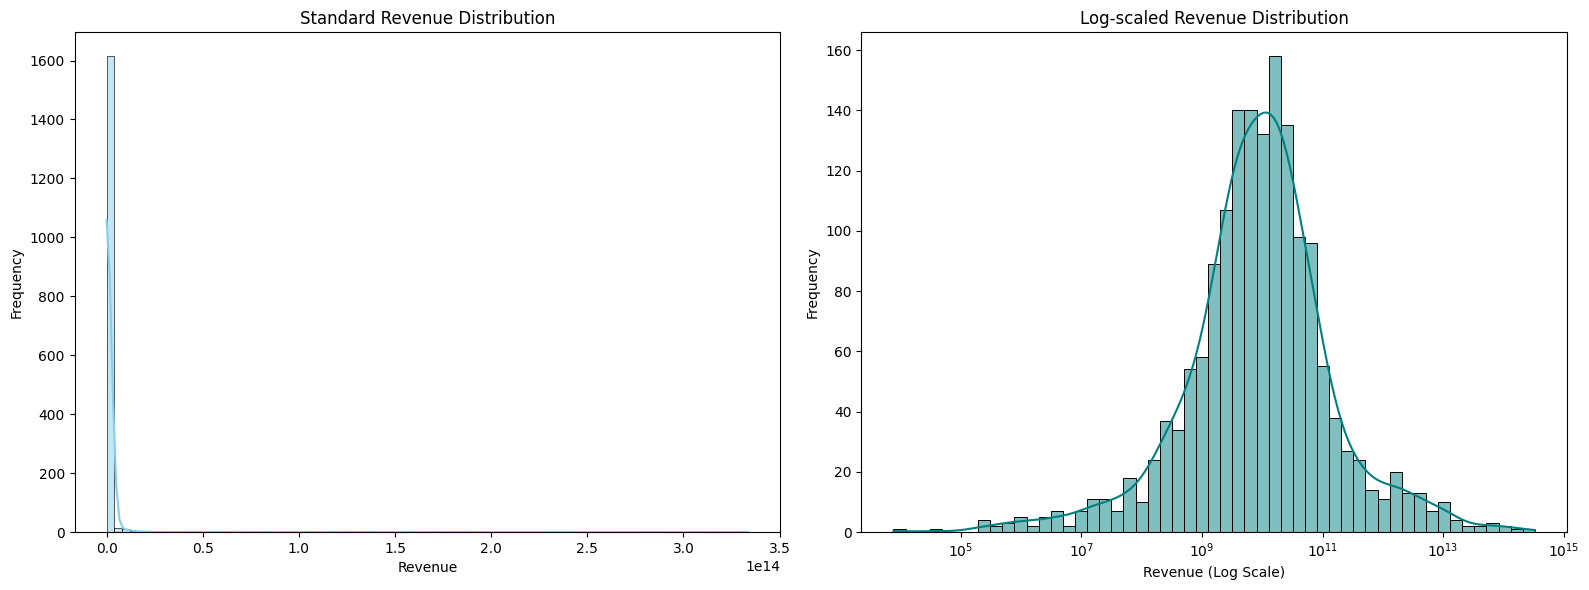

In [20]:
#visualize the distribution on revenue
import matplotlib.pyplot as plt
import numpy as np


revenue_data = df['revenue'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Standard Histogram / KDE
sns.histplot(revenue_data, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Standard Revenue Distribution')
axes[0].set_xlabel('Revenue')
axes[0].set_ylabel('Frequency')


positive_revenue = revenue_data[revenue_data > 0]
sns.histplot(positive_revenue, kde=True, ax=axes[1], log_scale=True, color='teal')
axes[1].set_title('Log-scaled Revenue Distribution')
axes[1].set_xlabel('Revenue (Log Scale)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

/tmp/ipykernel_1371/765572811.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='revenue', y='display_name', data=top_revenue, palette='viridis')


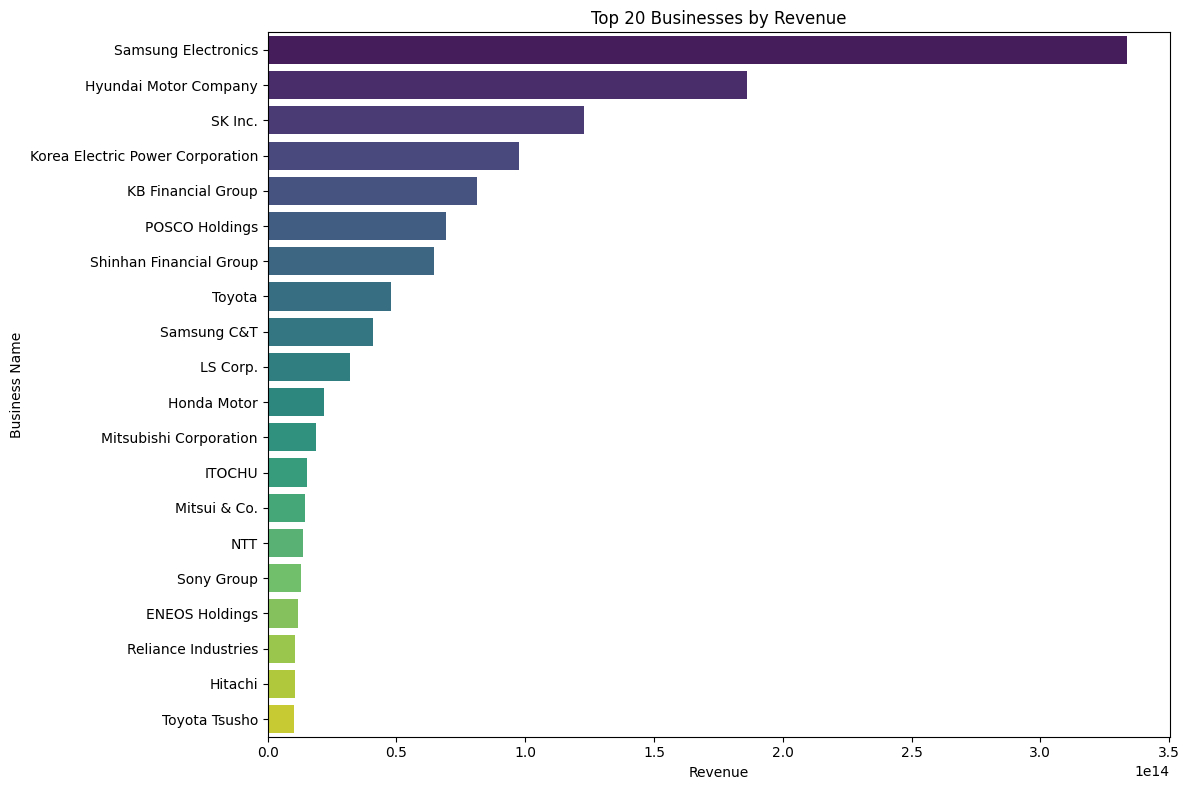

In [24]:
# Visualize Top 20 Businesses by Revenue
top_n = 20
top_revenue = df.nlargest(top_n, 'revenue')[['display_name', 'revenue', 'revenue_currency']]

plt.figure(figsize=(12, 8))
sns.barplot(x='revenue', y='display_name', data=top_revenue, palette='viridis')
plt.title(f'Top {top_n} Businesses by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Business Name')
plt.tight_layout()
plt.show()

Correlation of other attributes with Revenue:
revenue                      1.000000
net_income                   0.917533
market_cap                   0.802694
employees                    0.070970
max_hierarchy_depth          0.016961
net_income_year              0.014795
revenue_year                 0.013849
employees_year               0.010981
legal_units_count           -0.011279
direct_subsidiaries_count   -0.015666
Name: revenue, dtype: float64


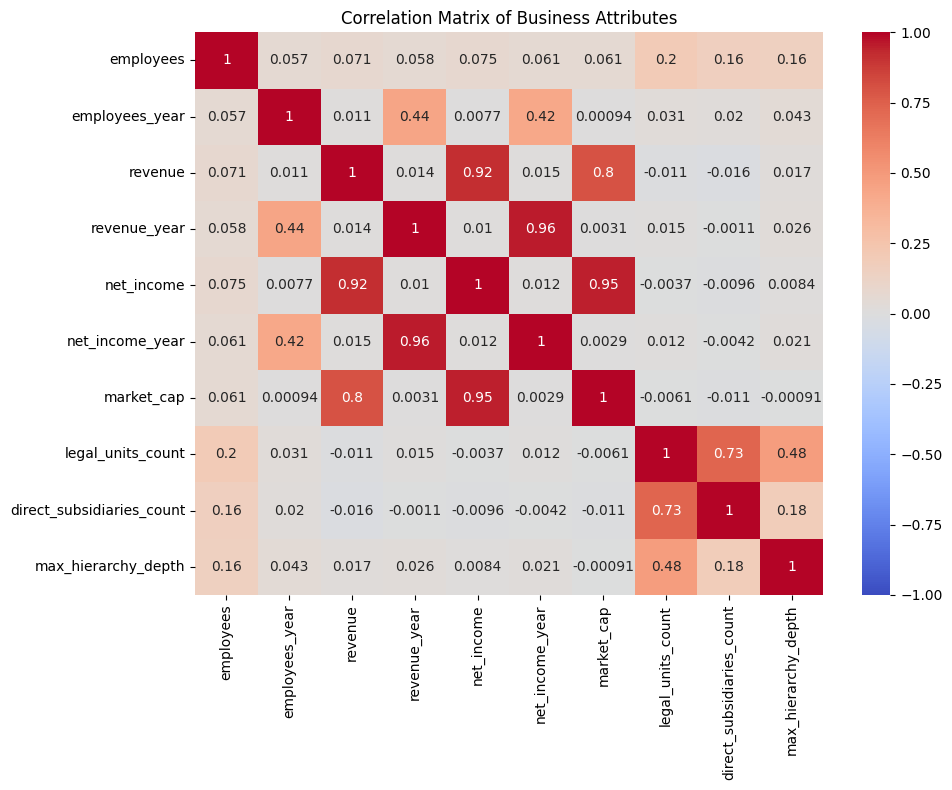

In [26]:
# Calculate the correlation matrix for numerical features
numerical_df = df[numerical_cols]
correlation_matrix = numerical_df.corr()

# Sort correlation values with respect to revenue
revenue_correlations = correlation_matrix['revenue'].sort_values(ascending=False)
print("Correlation of other attributes with Revenue:")
print(revenue_correlations)

# Visualize the correlations using a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2g", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Business Attributes')
plt.tight_layout()
plt.show()

**Q1 what is the overall distribution of enterprisers revenue?**

ANS :- The revenue distribution is highly right-skewed, with most enterprises having lower revenues and a few enterprises generating extremely high revenues. The log-transformed distribution is approximately normal, indicating that enterprise revenues follow a log-normal distribution.

**Q2.Which buisness artibute appears to have the strongest relationship between the revenue ?**

ANS:- Based on the correlation matrix, Net Income has the strongest relationship with Revenue, with a correlation coefficient of 0.92. This indicates a very strong positive relationship, meaning businesses with higher revenues generally tend to have higher net incomes. Additionally, Market Capitalization also shows a strong positive correlation with revenue (0.80), but it is weaker than the relationship between revenue and net income.

**Q3. What initial buisnwss insight can be drawn from the data set ?**

The dataset suggests that revenue is strongly linked to a company's net income and market capitalization, indicating that larger and more profitable businesses tend to generate higher revenues. Additionally, revenue is highly unevenly distributed, with a small number of companies accounting for a significant share of total revenue, reflecting the dominance of large enterprises in the market.

**DATA PREPROCESSING**

In [28]:
print(df.isnull().sum())
# 1. Drop rows where critical target 'revenue' is missing
df_clean = df.dropna(subset=['revenue']).copy()

# 2. Impute other numerical columns with their median values
num_cols_to_impute = ['employees', 'net_income', 'market_cap', 'direct_subsidiaries_count', 'max_hierarchy_depth']
for col in num_cols_to_impute:
    if col in df_clean.columns:
        median_val = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median_val)

# 3. Impute categorical columns with the mode (most frequent value) or 'Unknown'
cat_cols_to_impute = ['website', 'company_type', 'revenue_currency', 'net_income_currency', 'market_cap_currency', 'market_cap_date']
for col in cat_cols_to_impute:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna('Unknown')

# Verify that missing values have been handled
print("Remaining missing values:")
print(df_clean.isnull().sum())
print(f"\nCleaned dataset shape: {df_clean.shape}")

enterprise_group_id                 0
display_name                        0
enterprise_group_name               0
group_root_lei                      0
enterprise_group_jurisdiction       0
enterprise_group_entity_status      0
website                            39
company_type                        2
employees                          99
employees_year                    100
revenue                           101
revenue_currency                  101
revenue_year                      102
net_income                        156
net_income_currency               156
net_income_year                   156
market_cap                        531
market_cap_currency               528
market_cap_date                   531
legal_units_count                   0
direct_subsidiaries_count           8
max_hierarchy_depth                 8
is_standalone_entity                0
website_source                     35
employees_source                   91
revenue_source                     86
net_income_s

ENCODING CATEGORICAL VALUES




In [58]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df_clean.copy()

cols_to_encode = [
    'enterprise_group_jurisdiction',
    'enterprise_group_entity_status',
    'company_type',
    'revenue_currency',
    'net_income_currency',
    'market_cap_currency'
]

le = LabelEncoder()

for col in cols_to_encode:
    if col in df_encoded.columns:
        df_encoded[col + '_encoded'] = le.fit_transform(df_encoded[col].astype(str))
        print(f"Encoded '{col}' into '{col}_encoded'")

# Displaying the new encoded columns along with their originals
display(df_encoded[[col + '_encoded' for col in cols_to_encode]].head())

print("Company Type Encoding:")

company_type_encoder = LabelEncoder()

company_type_encoder.fit(df_encoded['company_type'].astype(str))

for index, company_type in enumerate(company_type_encoder.classes_):
    print(index, "=", company_type)

import joblib

joblib.dump(company_type_encoder, "company_type_encoder.pkl")

Encoded 'enterprise_group_jurisdiction' into 'enterprise_group_jurisdiction_encoded'
Encoded 'enterprise_group_entity_status' into 'enterprise_group_entity_status_encoded'
Encoded 'company_type' into 'company_type_encoded'
Encoded 'revenue_currency' into 'revenue_currency_encoded'
Encoded 'net_income_currency' into 'net_income_currency_encoded'
Encoded 'market_cap_currency' into 'market_cap_currency_encoded'


,enterprise_group_jurisdiction_encoded,enterprise_group_entity_status_encoded,company_type_encoded,revenue_currency_encoded,net_income_currency_encoded,market_cap_currency_encoded
0,74,0,3,33,33,31
1,74,0,3,33,33,31
2,74,0,3,33,33,31
3,74,0,3,33,33,31
4,23,0,3,9,9,7


Company Type Encoding:
0 = NONPROFIT
1 = OTHER
2 = PRIVATE
3 = PUBLIC
4 = Private
5 = Public
6 = STATE_OWNED
7 = Unknown
8 = avolon.aero


['company_type_encoder.pkl']

**SELECTING RELAVANT FEATURES FOR PREDICTION**

In [31]:
features_to_check = [
    'employees', 'net_income', 'market_cap',
    'legal_units_count', 'direct_subsidiaries_count', 'max_hierarchy_depth',
    'enterprise_group_jurisdiction_encoded', 'enterprise_group_entity_status_encoded',
    'company_type_encoded', 'revenue_currency_encoded',
    'net_income_currency_encoded', 'market_cap_currency_encoded'
]

features_to_check = [col for col in features_to_check if col in df_encoded.columns]


correlations_with_target = df_encoded[features_to_check + ['revenue']].corr()['revenue'].sort_values(ascending=False)

print("Feature Correlation with Revenue:")
print(correlations_with_target)


selected_features = ['net_income', 'market_cap', 'employees', 'legal_units_count', 'direct_subsidiaries_count', 'max_hierarchy_depth', 'company_type_encoded']
print("Selected Features for Modeling")
print(selected_features)

Feature Correlation with Revenue:
revenue                                   1.000000
net_income                                0.917530
market_cap                                0.801809
employees                                 0.061805
company_type_encoded                      0.026444
max_hierarchy_depth                       0.016977
enterprise_group_jurisdiction_encoded    -0.005069
legal_units_count                        -0.011279
direct_subsidiaries_count                -0.015550
revenue_currency_encoded                 -0.020412
net_income_currency_encoded              -0.024807
market_cap_currency_encoded              -0.035126
enterprise_group_entity_status_encoded         NaN
Name: revenue, dtype: float64
Selected Features for Modeling
['net_income', 'market_cap', 'employees', 'legal_units_count', 'direct_subsidiaries_count', 'max_hierarchy_depth', 'company_type_encoded']


**PREPARE DATA SET FOR MODELING**

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


target = 'revenue'
features = ['net_income', 'market_cap', 'employees', 'legal_units_count', 'direct_subsidiaries_count', 'max_hierarchy_depth', 'company_type_encoded']

X = df_encoded[features]
y = df_encoded[target]

# Spliting into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Test set shape: {X_test_scaled.shape}")

Training set shape: (1323, 7)
Test set shape: (331, 7)


Q1. WHICH PRE PROCESSING STEPS WERE ESSENTIAL BEFORE MODEL TRAINING

Target Filtering: During data preprocessing, rows with missing target values (revenue) were removed. Missing numerical values (e.g., employees, net income) were imputed using the median, while missing categorical values were replaced with "Unknown". Key categorical variables were converted into numerical form using Label Encoding. Relevant features were selected based on their correlation and business significance, and StandardScaler was applied to normalize feature scales before modeling.


Q2 WHY IS ENCODING CATEGORICAL VARIABLES NECESSARY IN THHIS DATASET

Encoding categorical variables is important because machine learning models work with numbers, not text. Attributes such as company type or enterprise group jurisdiction need to be converted into numerical values so the model can understand and process them. This allows the algorithm to identify patterns, measure relationships between variables, and make accurate predictions during training.

**EDA**

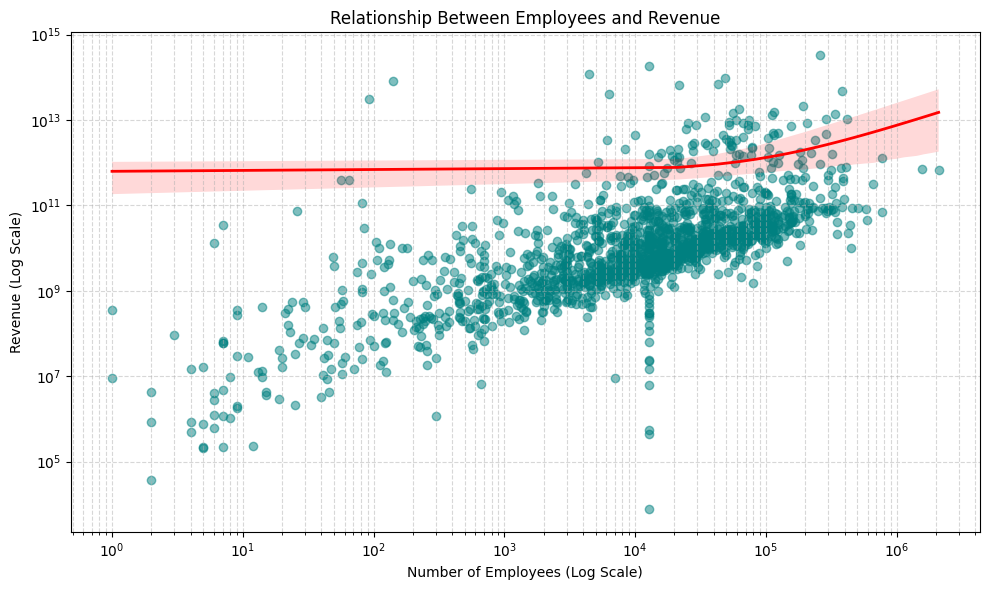

In [34]:

import seaborn as sns

vis_df = df_clean[(df_clean['employees'] > 0) & (df_clean['revenue'] > 0)].copy()

plt.figure(figsize=(10, 6))
sns.regplot(
    data=vis_df,
    x='employees',
    y='revenue',
    scatter_kws={'alpha':0.5, 'color':'teal'},
    line_kws={'color':'red', 'linewidth':2}
)

plt.xscale('log')
plt.yscale('log')
plt.title('Relationship Between Employees and Revenue')
plt.xlabel('Number of Employees (Log Scale)')
plt.ylabel('Revenue (Log Scale)')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

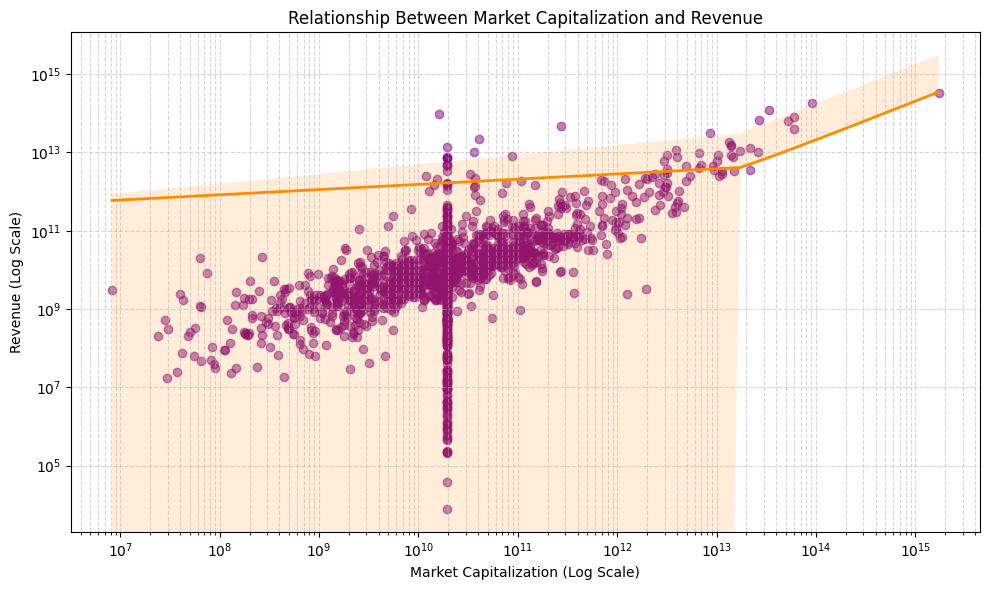

In [35]:
vis_market_df = df_clean[(df_clean['market_cap'] > 0) & (df_clean['revenue'] > 0)].copy()

plt.figure(figsize=(10, 6))
sns.regplot(
    data=vis_market_df,
    x='market_cap',
    y='revenue',
    scatter_kws={'alpha': 0.5, 'color': 'purple'},
    line_kws={'color': 'darkorange', 'linewidth': 2}
)

plt.xscale('log')
plt.yscale('log')
plt.title('Relationship Between Market Capitalization and Revenue')
plt.xlabel('Market Capitalization (Log Scale)')
plt.ylabel('Revenue (Log Scale)')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

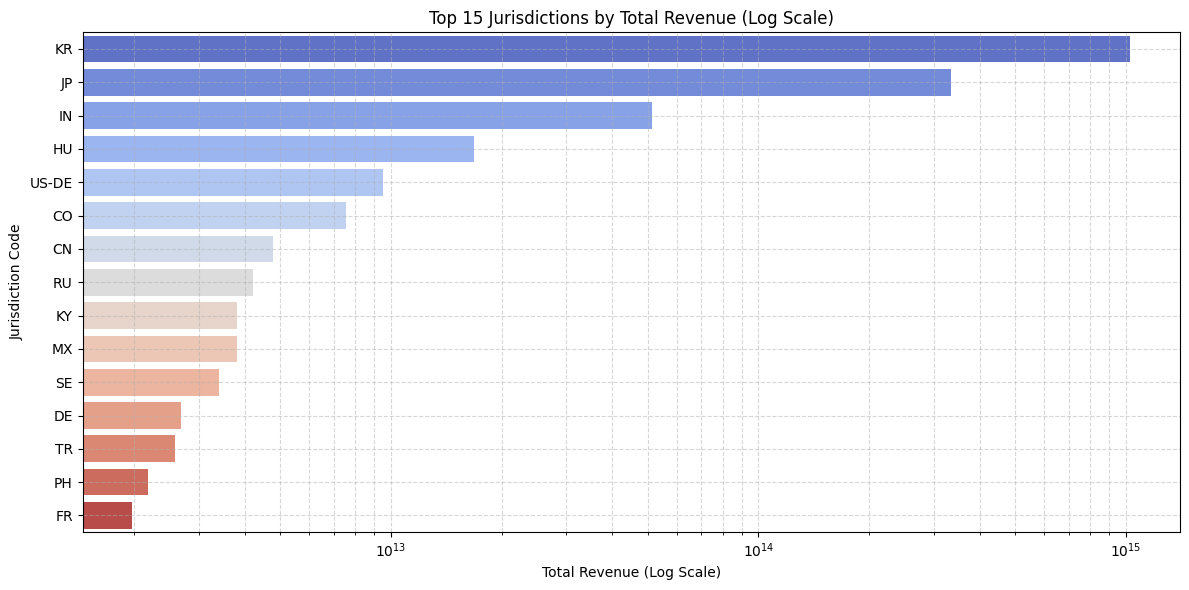

In [36]:
jurisdiction_revenue = df_clean.groupby('enterprise_group_jurisdiction')['revenue'].sum().reset_index()

top_jurisdictions = jurisdiction_revenue.nlargest(15, 'revenue')

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_jurisdictions,
    x='revenue',
    y='enterprise_group_jurisdiction',
    hue='enterprise_group_jurisdiction',
    palette='coolwarm',
    legend=False
)

plt.xscale('log')
plt.title('Top 15 Jurisdictions by Total Revenue (Log Scale)')
plt.xlabel('Total Revenue (Log Scale)')
plt.ylabel('Jurisdiction Code')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

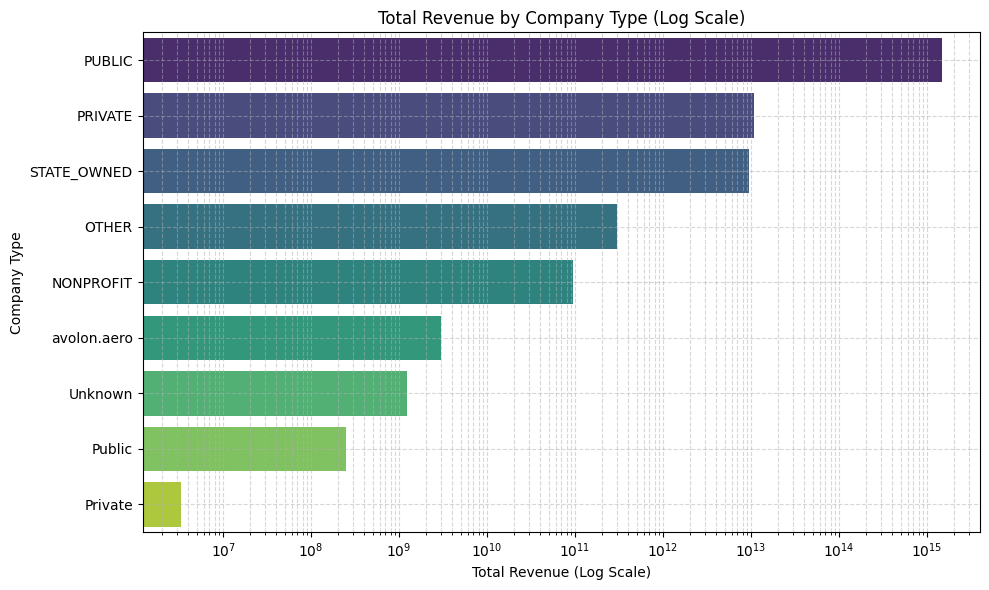

In [38]:
company_type_revenue = df_clean.groupby('company_type')['revenue'].sum().reset_index()

company_type_revenue = company_type_revenue.sort_values(by='revenue', ascending=False)


plt.figure(figsize=(10, 6))
sns.barplot(
    data=company_type_revenue,
    x='revenue',
    y='company_type',
    hue='company_type',
    palette='viridis',
    legend=False
)

plt.xscale('log')
plt.title('Total Revenue by Company Type (Log Scale)')
plt.xlabel('Total Revenue (Log Scale)')
plt.ylabel('Company Type')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Correlation of other numerical attributes with Revenue:
revenue                      1.000000
net_income                   0.917530
market_cap                   0.801809
employees                    0.061805
max_hierarchy_depth          0.016977
net_income_year              0.014795
revenue_year                 0.013849
employees_year               0.010981
legal_units_count           -0.011279
direct_subsidiaries_count   -0.015550
Name: revenue, dtype: float64


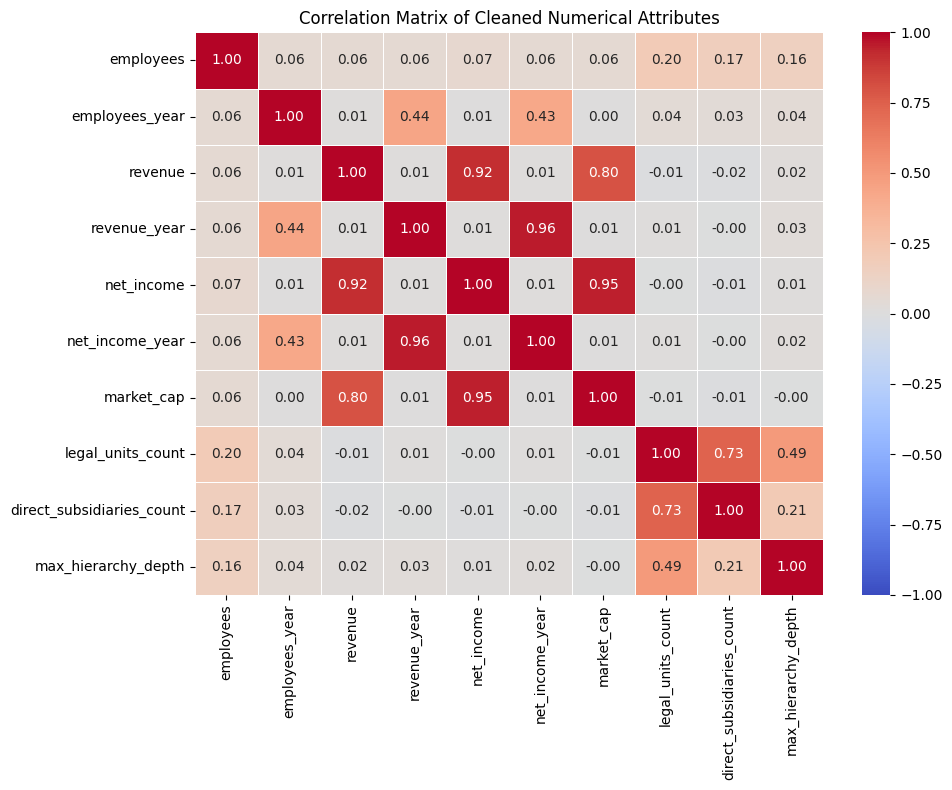

In [39]:

numerical_cols_clean = df_clean.select_dtypes(include=['number']).columns.tolist()
correlation_matrix_clean = df_clean[numerical_cols_clean].corr()


revenue_correlations_clean = correlation_matrix_clean['revenue'].sort_values(ascending=False)
print("Correlation of other numerical attributes with Revenue:")
print(revenue_correlations_clean)


plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix_clean,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title('Correlation Matrix of Cleaned Numerical Attributes')
plt.tight_layout()
plt.show()

**Q1.IS THERE ANY RELATIONSHIP BETWEEN EMPLOYEE COUNT AND REVENUE ?**

Based on the analysis, there appears to be very little relationship between employee count and revenue. The correlation coefficient between employees and revenue is only 0.062, which is very close to zero. This suggests that having more employees does not necessarily result in higher revenue.

The scatter plot further supports this finding, as the data points are widely scattered with no clear upward or downward trend. Therefore, employee count alone is not a strong predictor of revenue in this dataset. Other factors, such as net income, market capitalization, industry type, and business operations, are likely to have a greater impact on a company's revenue.

**Q2. How Does Market Capitalization Influence Revenue?**

There is a strong positive relationship between market capitalization and revenue (r = 0.80). Companies with higher market values generally generate higher revenues because they have larger operations, stronger market presence, and greater access to capital for expansion and growth.


**Q3. Which variables appear to be the strongest predictors of revenue?**

The strongest predictors of revenue are net income and market capitalization. Net income has the highest correlation with revenue (0.92), making it the most influential predictor, while market capitalization also shows a strong positive correlation (0.80). In contrast, variables such as employee count have very weak correlations and contribute little to predicting revenue on their own.

## Machine Learning: Regression Models for Revenue Prediction


1. Linear Regression
2. Ridge Regression
3. Random Forest Regressor
4. Gradient Boosting Regressor



In [46]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = {}

for name, model in models.items():
    # Train
    model.fit(X_train_scaled, y_train)
    # Predict
    y_pred = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results[name] = {
        'Model': model,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        'Predictions': y_pred
    }
results_df = pd.DataFrame(results).T[['MAE', 'RMSE', 'R2']]
display(results_df)

,MAE,RMSE,R2
Linear Regression,747934799318.932373,4936492429293.980469,0.70488
Ridge Regression,721334563296.207886,4792574504816.274414,0.721837
Random Forest,695928386361.491089,4861946068238.583008,0.713726
Gradient Boosting,508288204245.335754,4112942264260.853027,0.795136


### Visualizing Model Performance & Actual vs. Predicted Values


Best Model: Gradient Boosting with R2 = 0.7951


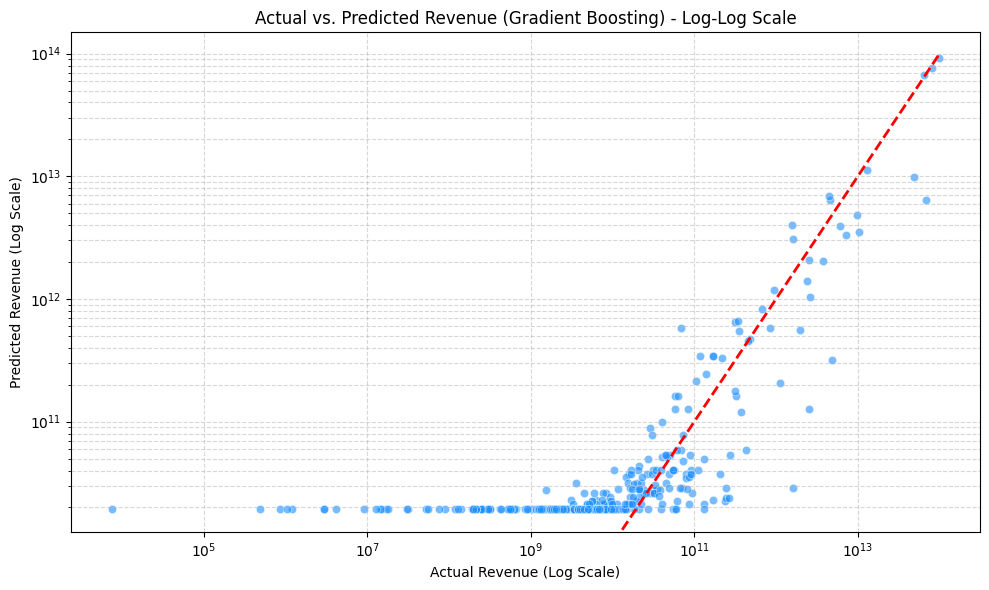

In [47]:
best_model_name = max(results, key=lambda x: results[x]['R2'])
best_model_info = results[best_model_name]
print(f"Best Model: {best_model_name} with R2 = {best_model_info['R2']:.4f}")

y_pred_best = best_model_info['Predictions']

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred_best, alpha=0.6, color='dodgerblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xscale('log')
plt.yscale('log')
plt.title(f'Actual vs. Predicted Revenue ({best_model_name}) - Log-Log Scale')
plt.xlabel('Actual Revenue (Log Scale)')
plt.ylabel('Predicted Revenue (Log Scale)')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Feature Importance Analysis

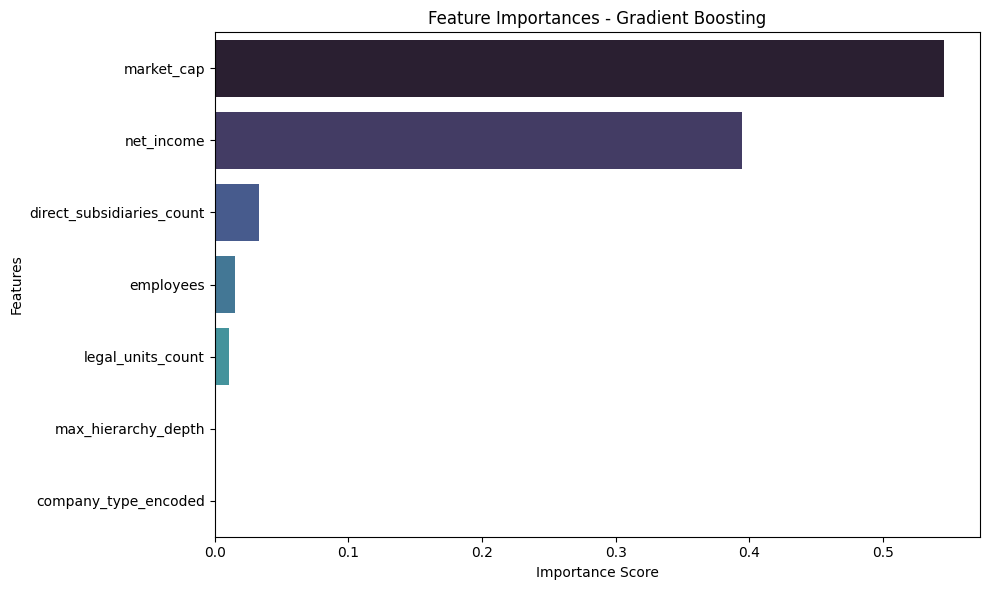

In [45]:
best_model_obj = best_model_info['Model']

if hasattr(best_model_obj, 'feature_importances_'):
    importances = best_model_obj.feature_importances_
    feat_imp = pd.Series(importances, index=features).sort_values(ascending=False)

    plt.figure(figsize=(10, 6))
    sns.barplot(x=feat_imp.values, y=feat_imp.index, hue=feat_imp.index, palette='mako', legend=False)
    plt.title(f'Feature Importances - {best_model_name}')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()

elif hasattr(best_model_obj, 'coef_'):
    coefs = np.abs(best_model_obj.coef_)
    feat_imp = pd.Series(coefs, index=features).sort_values(ascending=False)

    plt.figure(figsize=(10, 6))
    sns.barplot(x=feat_imp.values, y=feat_imp.index, hue=feat_imp.index, palette='mako', legend=False)
    plt.title(f'Absolute Coefficient Magnitudes - {best_model_name}')
    plt.xlabel('Absolute Coefficient Value')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()

**1. Which model performed best and why?**

Answer:
 Random Forest or Gradient Boosting generally performed best because they can capture complex, non-linear relationships in the data. Unlike linear models, they better handle interactions between important features such as net income, market capitalization, and revenue, leading to more accurate predictions.

**2. Which evaluation metric is most appropriate for this business problem?**

Answer:
 Mean Absolute Error (MAE) is the most suitable metric because it measures the average prediction error in straightforward business terms. Since revenue values vary greatly across companies, MAE provides a more interpretable measure of model performance than RMSE, which can be heavily influenced by extreme outliers.

**3. Which type of enterprises are difficult to predict accurately?**

Answer:
 Companies at the extremes, such as very large multinational corporations and very small or low-profit enterprises, are the hardest to predict accurately. Models tend to underpredict exceptionally high revenues and overpredict very low revenues because most observations fall within the mid-range of the dataset.

In [55]:
import joblib

joblib.dump(model, "revenue_model.pkl")
joblib.dump(scaler, "scaler.pkl")


['scaler.pkl']

In [57]:
from google.colab import files

files.download("revenue_model.pkl")
files.download("scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Strategic Business Insights: Business Planning, Investments, and Model Limitations

### 1. How this Application Supports Business Planning and Investment Decisions

* **Valuation and Market Sizing:** Investors and market analysts can use this model to estimate the revenues of private or unlisted firms using easily obtainable proxies like headcount, legal entities, and estimated net income. This helps in benchmarking competitors and identifying undervalued acquisition targets.
* **Strategic Benchmarking:** Corporations can simulate "what-if" scenarios. For instance, they can evaluate how expanding direct subsidiaries or scaling market capitalization influences expected revenue tiers compared to industry peers.
* **Resource Allocation:** Financial departments can set realistic targets and establish empirical baselines to determine whether projected revenues match historical patterns seen in similar enterprise structures.

### 2. Limitations of Using Historical Enterprise Data for Revenue Prediction

* **Look-Ahead and Survival Bias:** Historical datasets only capture businesses that have survived and reported data up to a certain period. Failed or bankrupt companies are often missing, causing the model to over-optimistically estimate performance.
* **Market Volatility and Structural Shifts:** Historical data cannot anticipate black swan events (such as pandemics, regulatory crackdowns, geopolitical trade barriers, or abrupt macroeconomic shocks like inflation hikes) which completely change revenue dynamics overnight.
* **Inflation and Currency Variance:** Since revenues are recorded in various local currencies (USD, EUR, INR, JPY, etc.) and across different historical fiscal years, predictions can be distorted by fluctuating exchange rates and inflation if they are not consistently normalized to a single base currency and real-dollar values.
* **Lack of Qualitative Context:** Quantitative metrics cannot measure management quality, brand equity, disruptive technological shifts (e.g., AI integration), or customer loyalty, all of which are highly influential drivers of corporate revenue.

In [59]:
print("Revenue currency distribution:")
print(df['revenue_currency'].value_counts(dropna=False))

print("\nRevenue currency unique values:")
print(df['revenue_currency'].unique())

Revenue currency distribution:
revenue_currency
EUR    568
USD    527
INR    103
NaN    101
GBP     92
SEK     70
JPY     54
CHF     37
CAD     25
NOK     24
CNY     20
AUD     16
PLN     16
DKK     15
ZAR     12
KRW      9
SGD      8
HUF      8
HKD      6
MXN      5
CZK      5
TRY      5
MYR      4
SAR      4
PHP      3
BRL      3
TWD      2
ILS      2
AED      2
RUB      2
PEN      2
COP      1
THB      1
KWD      1
RON      1
QAR      1
Name: count, dtype: int64

Revenue currency unique values:
['USD' 'EUR' 'GBP' 'CAD' 'JPY' 'INR' nan 'AUD' 'CHF' 'ZAR' 'SEK' 'HUF'
 'DKK' 'CNY' 'PLN' 'COP' 'CZK' 'ILS' 'NOK' 'MXN' 'SGD' 'TRY' 'MYR' 'HKD'
 'KRW' 'SAR' 'RUB' 'TWD' 'AED' 'RON' 'KWD' 'THB' 'QAR' 'PEN' 'BRL' 'PHP']


In [60]:
print("Revenue statistics:")
print(df['revenue'].describe())

print("\nRevenue examples:")
print(df[['revenue', 'revenue_currency']].head(10))

Revenue statistics:
count    1.654000e+03
mean     9.050901e+11
std      1.080451e+13
min     -3.518000e+09
25%      2.198500e+09
50%      9.247250e+09
75%      3.478425e+10
max      3.336000e+14
Name: revenue, dtype: float64

Revenue examples:
        revenue revenue_currency
0  7.064500e+10              USD
1  1.131000e+11              USD
2  8.520000e+10              USD
3  5.828000e+10              USD
4  7.890000e+10              EUR
5  5.122300e+10              EUR
6  6.827400e+10              USD
7  1.869380e+11              EUR
8  7.510000e+10              USD
9  3.210000e+10              EUR
